<a href="https://colab.research.google.com/github/Rosaura18/fashion-mnist-cnn/blob/main/Rosaura_CNN_FashionMNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install datasets scikit-learn
import random, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import datasets, sklearn
import sys; print("python", sys.version.split()[0])
from datasets import load_dataset
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| datasets", datasets.__version__,
      "| sklearn", sklearn.__version__, "| device", device, "| seed", SEED)

python 3.13.16
torch 2.14.1+cu130 | datasets 4.8.5 | sklearn 1.6.1 | device cuda | seed 42


In [2]:
ds = load_dataset("zalando-datasets/fashion_mnist")
split = ds["train"].train_test_split(test_size=0.1, seed=SEED)
train_ds, val_ds, test_ds = split["train"], split["test"], ds["test"]
print(len(train_ds), len(val_ds), len(test_ds))   # 54000 / 6000 / 10000

def collate(batch):
    x = torch.tensor(np.stack([np.array(b["image"]) for b in batch]),
                     dtype=torch.float32).div(255).unsqueeze(1)   # (B,1,28,28)
    y = torch.tensor([b["label"] for b in batch])
    return x, y

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  collate_fn=collate)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, collate_fn=collate)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, collate_fn=collate)

README.md:   0%|          | 0.00/9.02k [00:00<?, ?B/s]

fashion_mnist/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 30.9MB            

fashion_mnist/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

fashion_mnist/test-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 5.18MB            

fashion_mnist/test-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

54000 6000 10000


In [3]:
class SimpleCNN(nn.Module):
    def __init__(self, c1=16, c2=32, hidden=64):
        super().__init__()
        self.c1, self.c2 = c1, c2
        self.conv1 = nn.Conv2d(1, c1, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(c1, c2, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(c2 * 7 * 7, hidden)
        self.fc2 = nn.Linear(hidden, 10)

    def forward(self, x, verbose=False):
        B = x.shape[0]
        assert x.shape[1:] == (1, 28, 28), x.shape
        x = F.relu(self.conv1(x)); assert x.shape == (B, self.c1, 28, 28)
        x = F.max_pool2d(x, 2);    assert x.shape == (B, self.c1, 14, 14)
        x = F.relu(self.conv2(x)); assert x.shape == (B, self.c2, 14, 14)
        x = F.max_pool2d(x, 2);    assert x.shape == (B, self.c2, 7, 7)
        x = x.flatten(1);          assert x.shape == (B, self.c2 * 49)
        x = F.relu(self.fc1(x))
        x = self.fc2(x);           assert x.shape == (B, 10)
        if verbose: print("final logits:", x.shape)
        return x

# Print each shape once for your screenshot
m = SimpleCNN().to(device)
xb, yb = next(iter(train_dl))
print("input:", xb.shape, "labels:", yb.shape)
h = xb.to(device)
h = F.relu(m.conv1(h)); print("after conv1:", h.shape)
h = F.max_pool2d(h, 2); print("after pool1:", h.shape)
h = F.relu(m.conv2(h)); print("after conv2:", h.shape)
h = F.max_pool2d(h, 2); print("after pool2:", h.shape)
h = h.flatten(1);       print("flattened:  ", h.shape)
print("output logits:", m(xb.to(device)).shape)

input: torch.Size([128, 1, 28, 28]) labels: torch.Size([128])
after conv1: torch.Size([128, 16, 28, 28])
after pool1: torch.Size([128, 16, 14, 14])
after conv2: torch.Size([128, 32, 14, 14])
after pool2: torch.Size([128, 32, 7, 7])
flattened:   torch.Size([128, 1568])
output logits: torch.Size([128, 10])


In [4]:
def evaluate(model, dl):
    model.eval(); correct = total = 0; loss_sum = 0; preds, labels = [], []
    with torch.no_grad():
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += F.cross_entropy(out, y, reduction="sum").item()
            p = out.argmax(1)
            correct += (p == y).sum().item(); total += len(y)
            preds += p.cpu().tolist(); labels += y.cpu().tolist()
    return loss_sum / total, correct / total, preds, labels

def train(model, lr=1e-3, epochs=5):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train()
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward(); opt.step()
        vl, va, _, _ = evaluate(model, val_dl)
        print(f"epoch {ep+1}: val_loss={vl:.4f} val_acc={va:.4f}")
    return model

In [6]:
torch.manual_seed(SEED)
model_A = train(SimpleCNN(c1=16, c2=32).to(device))   # original

torch.manual_seed(SEED)
model_B = train(SimpleCNN(c1=32, c2=64).to(device))   # modified: more filters

epoch 1: val_loss=0.4051 val_acc=0.8560
epoch 2: val_loss=0.3554 val_acc=0.8728
epoch 3: val_loss=0.3352 val_acc=0.8753
epoch 4: val_loss=0.2904 val_acc=0.8947
epoch 5: val_loss=0.2967 val_acc=0.8918
epoch 1: val_loss=0.4203 val_acc=0.8445
epoch 2: val_loss=0.3123 val_acc=0.8848
epoch 3: val_loss=0.3182 val_acc=0.8825
epoch 4: val_loss=0.2579 val_acc=0.9042
epoch 5: val_loss=0.2546 val_acc=0.9058


In [7]:
vl_A, va_A, _, _ = evaluate(model_A, val_dl)
vl_B, va_B, _, _ = evaluate(model_B, val_dl)
print(f"Validation: A acc={va_A:.4f} loss={vl_A:.4f} | B acc={va_B:.4f} loss={vl_B:.4f}")
best = "B" if va_B > va_A else "A"
print("Selected on VALIDATION data:", best)

Validation: A acc=0.8918 loss=0.2967 | B acc=0.9058 loss=0.2546
Selected on VALIDATION data: B


In [8]:
names = ds["train"].features["label"].names
for tag, mdl in [("A (original)", model_A), ("B (modified)", model_B)]:
    tl, ta, p, y = evaluate(mdl, test_dl)
    print(f"\n=== Model {tag}: test loss {tl:.4f}, test acc {ta:.4f} ===")
    print(classification_report(y, p, target_names=names, digits=4))
    print(confusion_matrix(y, p))


=== Model A (original): test loss 0.3151, test acc 0.8881 ===
                 precision    recall  f1-score   support

T - shirt / top     0.8246    0.8700    0.8467      1000
        Trouser     0.9733    0.9840    0.9786      1000
       Pullover     0.9101    0.7190    0.8034      1000
          Dress     0.9100    0.8700    0.8896      1000
           Coat     0.7628    0.8650    0.8107      1000
         Sandal     0.9877    0.9620    0.9747      1000
          Shirt     0.6835    0.7190    0.7008      1000
        Sneaker     0.9095    0.9850    0.9458      1000
            Bag     0.9779    0.9740    0.9760      1000
     Ankle boot     0.9831    0.9330    0.9574      1000

       accuracy                         0.8881     10000
      macro avg     0.8923    0.8881    0.8884     10000
   weighted avg     0.8923    0.8881    0.8884     10000

[[870   1   6  22   9   1  83   0   8   0]
 [  1 984   0  12   2   0   0   0   1   0]
 [ 21   2 719   9 136   0 112   0   1   0]
 [ 22  

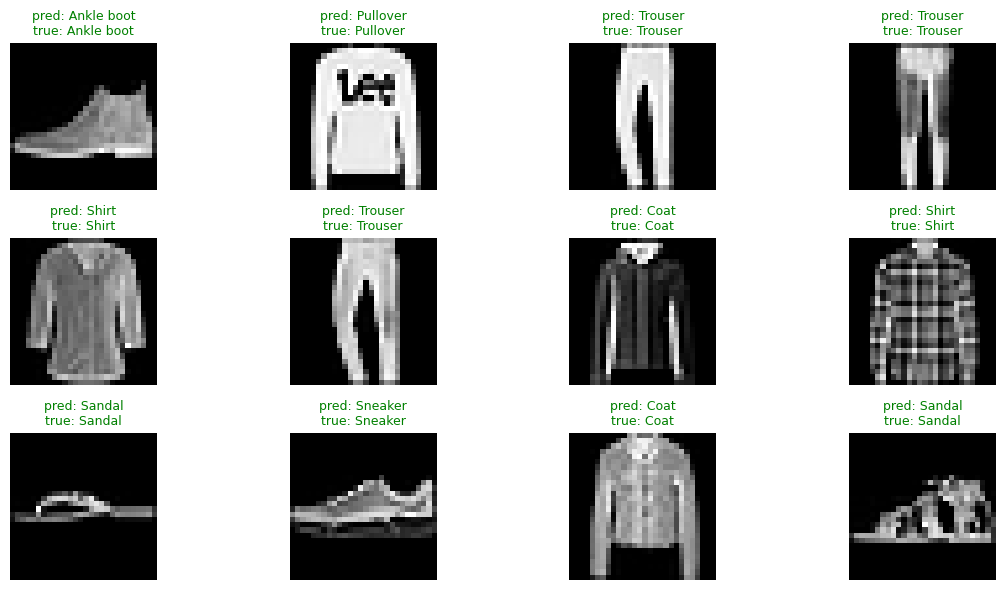

In [9]:
import matplotlib.pyplot as plt

names = ds["train"].features["label"].names   # class names
model_A.eval()

xb, yb = next(iter(test_dl))                  # one batch from the TEST set
with torch.no_grad():
    preds = model_A(xb.to(device)).argmax(1).cpu()

plt.figure(figsize=(12, 6))
for i in range(12):                           # show first 12 images
    plt.subplot(3, 4, i + 1)
    plt.imshow(xb[i].squeeze(), cmap="gray")  # (1,28,28) -> (28,28)
    color = "green" if preds[i] == yb[i] else "red"
    plt.title(f"pred: {names[preds[i]]}\ntrue: {names[yb[i]]}", color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()